# 04 — Matrix Factorization (SGD)

**Ide dasar:** ada "fitur tersembunyi" (*latent features*) yang menentukan apakah seorang user menyukai
sebuah film, misalnya seberapa banyak unsur aksi, romantis, atau film klasik. Fitur ini tidak tertulis di
data, tetapi bisa **dipelajari dari pola rating**.

Matriks rating $R$ (user × film) didekati dengan perkalian dua matriks yang jauh lebih kecil:

$$R \approx \hat{R} = P \times Q^T$$

- $P$ berukuran (jumlah user × K): baris ke-i = selera user i terhadap K fitur
- $Q$ berukuran (jumlah film × K): baris ke-j = kadar K fitur tersebut pada film j
- Prediksi rating user i untuk film j = **dot product** kedua baris tersebut:

$$\hat{r}_{ij} = p_i \cdot q_j = \sum_{k=1}^{K} p_{ik}\, q_{kj}$$

Analogi: jika fitur ke-1 adalah "aksi", user penyuka aksi punya $p_{i1}$ besar, film aksi punya $q_{1j}$
besar, sehingga perkaliannya besar → prediksi rating tinggi.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
FIG = ROOT / "figures"; FIG.mkdir(exist_ok=True)
RES = ROOT / "results"; RES.mkdir(exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src import plot_style as ps
ps.setup()
pd.set_option("display.precision", 4)
from src.data import load_fold, load_ratings, load_items, to_matrix, unique_titles
from src.metrics import evaluate
from src.mf import MatrixFactorization

## Langkah 0 — Mengulang contoh di slide M04

Kode slide memakai matriks 5 user × 4 film, K = 2 fitur, learning rate α = 0,0002, regularisasi β = 0,02,
dan 5.000 iterasi, dengan P dan Q diisi angka acak 0–1. Sel kosong (di slide ditulis 0) tidak ikut dilatih.

In [2]:
nan = np.nan
R_slide = np.array([[5, 3, nan, 1],
                    [4, nan, nan, 1],
                    [1, 1, nan, 5],
                    [1, nan, nan, 4],
                    [nan, 1, 5, 4]])
mf_slide = MatrixFactorization(K=2, alpha=0.0002, beta=0.02, epochs=5000, init="slide", seed=0).fit(R_slide)
idx, col = [f"U{i}" for i in range(1, 6)], [f"D{j}" for j in range(1, 5)]
print("Matriks asli (NaN = belum ada rating):")
display(pd.DataFrame(R_slide, index=idx, columns=col))
print("Hasil pendekatan P x Q^T:")
display(pd.DataFrame(mf_slide.P @ mf_slide.Q.T, index=idx, columns=col).round(2))
print(f"RMSE pada rating yang diketahui: awal {mf_slide.history[0]['rmse_train']:.3f} -> akhir {mf_slide.history[-1]['rmse_train']:.3f}")

Matriks asli (NaN = belum ada rating):


,D1,D2,D3,D4
U1,5.0,3.0,NaN,1.0
U2,4.0,NaN,NaN,1.0
U3,1.0,1.0,NaN,5.0
U4,1.0,NaN,NaN,4.0
U5,NaN,1.0,5.0,4.0


Hasil pendekatan P x Q^T:


,D1,D2,D3,D4
U1,4.98,2.97,3.47,1.00
U2,3.97,2.38,2.98,1.00
U3,1.04,0.91,5.72,4.96
U4,0.98,0.82,4.65,3.98
U5,1.47,1.11,4.94,4.02


RMSE pada rating yang diketahui: awal 2.440 -> akhir 0.040


Rating yang diketahui berhasil "diulang" dengan sangat dekat, dan sel yang kosong kini terisi prediksi.
Polanya sama dengan slide: U1 dan U2 menyukai D1 dan tidak menyukai D4, sedangkan U3–U5 sebaliknya. Angka
prediksi untuk sel kosong tidak persis sama dengan slide karena angka acak awalnya berbeda.

## Langkah 1 — Bagaimana P dan Q dilatih (Stochastic Gradient Descent)

Untuk setiap rating yang diketahui:

1. Hitung error: $e_{ij} = r_{ij} - p_i \cdot q_j$
2. Geser $p_i$ dan $q_j$ sedikit ke arah yang mengecilkan error (rumus slide, dengan regularisasi β):

$$p_{ik} \leftarrow p_{ik} + \alpha\,(2\, e_{ij}\, q_{kj} - \beta\, p_{ik})$$
$$q_{kj} \leftarrow q_{kj} + \alpha\,(2\, e_{ij}\, p_{ik} - \beta\, q_{kj})$$

- **α (learning rate)** = besar langkah. Terlalu kecil → belajar sangat lambat; terlalu besar → tidak stabil.
- **β (regularisasi)** = "rem" agar angka di P dan Q tidak membesar hanya demi menghafal data latih.
- **Satu epoch** = semua rating latih sudah dipakai sekali. Urutan rating diacak setiap epoch (inilah arti
  *stochastic*).

Contoh satu langkah dengan angka kecil (K = 2):

In [3]:
p = np.array([1.0, 0.5]); q = np.array([1.2, 0.8]); r = 4; alpha, beta = 0.01, 0.02
pred = p @ q
e = r - pred
p_baru = p + alpha * (2 * e * q - beta * p)
q_baru = q + alpha * (2 * e * p - beta * q)
print(f"prediksi awal = 1.0*1.2 + 0.5*0.8 = {pred:.4f}")
print(f"error e       = {r} - {pred:.4f} = {e:.4f}")
print(f"p baru        = {p} + 0.01*(2*{e:.2f}*{q} - 0.02*{p}) = {p_baru.round(4)}")
print(f"q baru        = {q_baru.round(4)}")
print(f"prediksi baru = {p_baru @ q_baru:.4f}  (lebih dekat ke {r})")

prediksi awal = 1.0*1.2 + 0.5*0.8 = 1.6000
error e       = 4 - 1.6000 = 2.4000
p baru        = [1.  0.5] + 0.01*(2*2.40*[1.2 0.8] - 0.02*[1.  0.5]) = [1.0574 0.5383]
q baru        = [1.2478 0.8238]
prediksi baru = 1.7629  (lebih dekat ke 4)


## Langkah 2 — Memilih hyperparameter dengan data validasi

Pengaturan slide (α = 0,0002, 5.000 iterasi) cocok untuk matriks mainan berisi 12 rating. Untuk 80.000
rating, satu epoch butuh hampir 1 detik, sehingga 5.000 epoch akan memakan lebih dari 1 jam per fold.
Karena itu K, α, β, dan jumlah epoch dipilih ulang.

**Penting:** pemilihan dilakukan **tanpa** melihat data uji. Data latih fold 1 dibagi lagi menjadi 90% untuk
melatih dan 10% sebagai **data validasi**. Proses ini dijalankan oleh `scripts/mf_tuning.py` (sekitar 10 menit),
dan hasilnya dibaca di sini.

Pencarian dilakukan bertahap:
1. **Learning rate:** α = 0,0002 (slide), 0,005, dan 0,01.
2. **K dan β:** K = 5, 10, 20, 50 dengan β = 0,02 dan 0,1.
3. **Perluasan:** hasil terbaik tahap 2 berada di ujung grid (K dan β terbesar), sehingga grid diperluas ke
   β = 0,2 dan K = 100.
4. **Perluasan kedua:** hasil terbaik masih di ujung, sehingga diperluas lagi ke β = 0,3 dan 0,5, K = 200,
   dan maksimal 100 epoch. Pada tahap ini nilai terbaik sudah berada di tengah grid (β = 0,3 dan K = 200
   sama-sama lebih buruk), sehingga pencarian dihentikan.

In [4]:
tun = pd.read_csv(RES / "mf_tuning.csv")
tun["config"] = tun.apply(lambda r: f"K={r.K:.0f}, α={r.alpha:g}, β={r.beta:g}", axis=1)
best_per_cfg = (tun.loc[tun.groupby("config")["rmse_val"].idxmin()]
                [["tahap", "K", "alpha", "beta", "epoch", "rmse_train", "rmse_val"]]
                .rename(columns={"epoch": "epoch terbaik", "rmse_train": "RMSE latih", "rmse_val": "RMSE validasi"})
                .sort_values("RMSE validasi"))
best_per_cfg.reset_index(drop=True)

,tahap,K,alpha,beta,epoch terbaik,RMSE latih,RMSE validasi
0,perluasan,100,0.0100,0.20,35,0.6281,0.9140
1,perluasan 2,200,0.0100,0.20,43,0.6080,0.9157
2,perluasan,50,0.0100,0.20,48,0.6299,0.9185
3,perluasan 2,50,0.0100,0.30,100,0.7785,0.9249
4,perluasan 2,100,0.0100,0.30,64,0.7804,0.9257
5,perluasan 2,200,0.0100,0.30,84,0.7740,0.9262
6,perluasan,100,0.0100,0.10,17,0.4527,0.9274
7,perluasan,20,0.0100,0.20,56,0.6936,0.9276
8,K dan beta,50,0.0100,0.10,10,0.6533,0.9413
9,K dan beta,5,0.0100,0.10,26,0.8214,0.9439


Ringkasan RMSE validasi terbaik untuk setiap kombinasi K dan β (α = 0,01). Sel kosong = tidak dicoba.

In [5]:
grid = best_per_cfg[best_per_cfg["alpha"] == 0.01].pivot_table(index="K", columns="beta", values="RMSE validasi", aggfunc="min")
grid.columns = [f"β = {b:g}" for b in grid.columns]
grid.index = [f"K = {k:.0f}" for k in grid.index]
grid.round(4)

,β = 0.02,β = 0.1,β = 0.2,β = 0.3,β = 0.5
K = 5,0.9621,0.9439,NaN,NaN,NaN
K = 10,0.9796,0.9580,NaN,NaN,NaN
K = 20,0.9732,0.9543,0.9276,NaN,NaN
K = 50,0.9663,0.9413,0.9185,0.9249,NaN
K = 100,NaN,0.9274,0.9140,0.9257,0.9686
K = 200,NaN,NaN,0.9157,0.9262,NaN


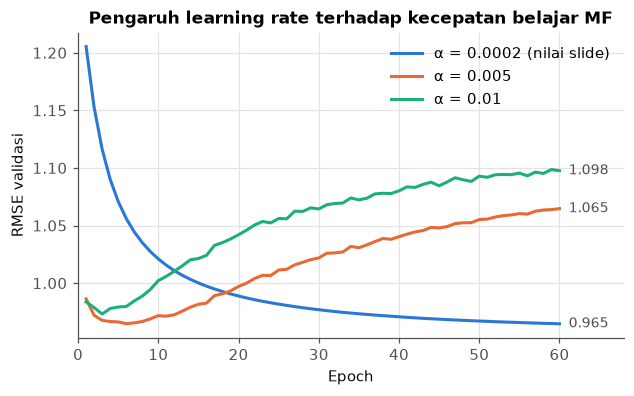

In [6]:
lr = tun[tun["tahap"] == "learning rate"]
fig, ax = plt.subplots(figsize=(6.4, 3.6))
for (alpha, g), color in zip(lr.groupby("alpha"), [ps.BLUE, ps.ORANGE, ps.AQUA]):
    label = f"α = {alpha:g}" + (" (nilai slide)" if alpha == 0.0002 else "")
    ax.plot(g["epoch"], g["rmse_val"], color=color, label=label)
    ax.annotate(f"{g['rmse_val'].iloc[-1]:.3f}", (g["epoch"].iloc[-1], g["rmse_val"].iloc[-1]),
                xytext=(6, 0), textcoords="offset points", va="center", fontsize=9, color=ps.INK_2)
ax.set_xlabel("Epoch")
ax.set_ylabel("RMSE validasi")
ax.set_title("Pengaruh learning rate terhadap kecepatan belajar MF")
ax.set_xlim(0, 68)
ax.legend(loc="upper right")
fig.savefig(FIG / "mf_learning_rate.png")
plt.show()

Konfigurasi akhir = konfigurasi dengan **RMSE validasi terkecil**, beserta epoch tempat nilai itu dicapai.

In [7]:
pilih = best_per_cfg.iloc[0]
K, ALPHA, BETA, EPOCHS = int(pilih["K"]), float(pilih["alpha"]), float(pilih["beta"]), int(pilih["epoch terbaik"])
print(f"Konfigurasi terpilih: K = {K}, alpha = {ALPHA}, beta = {BETA}, epochs = {EPOCHS}")
print(f"RMSE validasi = {pilih['RMSE validasi']:.4f}")

Konfigurasi terpilih: K = 100, alpha = 0.01, beta = 0.2, epochs = 35
RMSE validasi = 0.9140


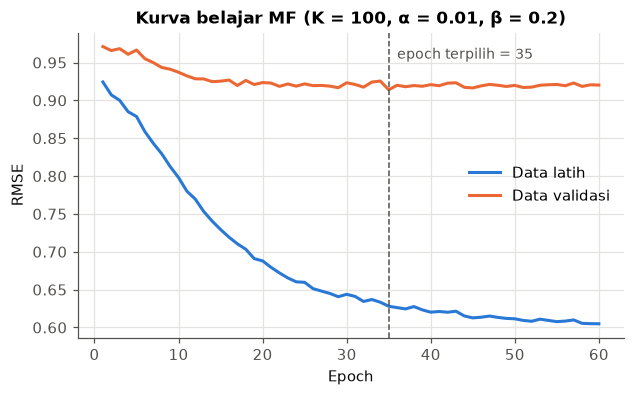

In [8]:
g = tun[tun["config"] == f"K={K}, α={ALPHA:g}, β={BETA:g}"]
fig, ax = plt.subplots(figsize=(6.4, 3.6))
ax.plot(g["epoch"], g["rmse_train"], color=ps.BLUE, label="Data latih")
ax.plot(g["epoch"], g["rmse_val"], color=ps.ORANGE, label="Data validasi")
ax.axvline(EPOCHS, color=ps.INK_2, linestyle="--", linewidth=1)
ax.text(EPOCHS + 1, ax.get_ylim()[1] * 0.98, f"epoch terpilih = {EPOCHS}", color=ps.INK_2, fontsize=9, va="top")
ax.set_xlabel("Epoch")
ax.set_ylabel("RMSE")
ax.set_title(f"Kurva belajar MF (K = {K}, α = {ALPHA:g}, β = {BETA:g})")
ax.legend(loc="center right")
fig.savefig(FIG / "mf_kurva_belajar.png")
plt.show()

Kurva latih terus turun, tetapi kurva validasi mendatar setelah sekitar epoch 20. Setelah titik itu model
makin hafal data latih, tetapi tidak makin pintar menebak rating yang belum pernah ia lihat. Pelatihan
dihentikan di epoch dengan RMSE validasi terkecil (*early stopping*).

Bandingkan dengan grafik learning rate sebelumnya yang memakai β = 0,02: di sana RMSE validasi justru
**naik terus** setelah beberapa epoch. Itulah **overfitting**: angka di P dan Q membesar demi menghafal
data latih. Dengan β = 0,2, regularisasi menahan hal tersebut sehingga kurva validasi tidak naik.

## Langkah 3 — Melatih di fold 1 dan membuat satu prediksi

In [9]:
train, test = load_fold(1)
R = to_matrix(train)
titles = load_items()
model = MatrixFactorization(K=K, alpha=ALPHA, beta=BETA, epochs=EPOCHS).fit(R)

contoh = test[test["user"] == 1].iloc[0]
u, i = contoh["user"] - 1, contoh["item"] - 1
print(f"Setiap vektor berisi K = {K} angka; ditampilkan 10 angka pertama saja.")
print(f"Vektor selera user {u+1}       p = {model.P[u][:10].round(3)} ...")
print(f"Vektor film '{titles[i+1][:20]}...' q = {model.Q[i][:10].round(3)} ...")
kontribusi = model.P[u] * model.Q[i]
print(f"p1*q1 + p2*q2 + ... = {kontribusi[0]:.4f} + {kontribusi[1]:.4f} + ... (total {K} suku)")
print(f"Prediksi = p . q = {model.P[u] @ model.Q[i]:.4f}, rating asli = {contoh['rating']}")

Setiap vektor berisi K = 100 angka; ditampilkan 10 angka pertama saja.
Vektor selera user 1       p = [0.221 0.296 0.05  0.287 0.036 0.28  0.289 0.171 0.158 0.145] ...
Vektor film 'Shanghai Triad (Yao ...' q = [ 0.173  0.267 -0.017  0.292  0.102  0.303  0.236  0.33   0.369  0.196] ...
p1*q1 + p2*q2 + ... = 0.0383 + 0.0789 + ... (total 100 suku)
Prediksi = p . q = 3.2857, rating asli = 5


## Langkah 4 — Evaluasi fold 1

In [10]:
pred = model.predict_df(test)
display(pred.head(8))
pd.Series(evaluate(pred)).to_frame("MF fold 1")

,user,item,rating,timestamp,pred
0,1,6,5,887431973,3.2857
1,1,10,3,875693118,4.0780
2,1,12,5,878542960,4.5683
3,1,14,5,874965706,4.1180
4,1,17,3,875073198,3.2764
5,1,20,4,887431883,3.5311
6,1,23,4,875072895,4.4025
7,1,24,3,875071713,4.0422


,MF fold 1
MAE,0.7441
MSE,0.8712
RMSE,0.9334
NMSE,0.2178
NDCG@10,0.8529


## Langkah 5 — Evaluasi di kelima fold

Konfigurasi yang sama dipakai untuk kelima fold. Bagian ini butuh beberapa menit.

In [11]:
rows = []
for k in range(1, 6):
    tr, te = load_fold(k)
    m = MatrixFactorization(K=K, alpha=ALPHA, beta=BETA, epochs=EPOCHS).fit(to_matrix(tr))
    rows.append({"Fold": k, **evaluate(m.predict_df(te))})
mf_5fold = pd.DataFrame(rows).set_index("Fold")
mf_5fold.loc["Rata-rata"] = mf_5fold.mean()
mf_5fold.loc["Simpangan baku"] = mf_5fold.iloc[:5].std()
mf_5fold.to_csv(RES / "mf_5fold.csv")
pd.Series({"K": K, "alpha": ALPHA, "beta": BETA, "epochs": EPOCHS}).to_csv(RES / "mf_config.csv", header=["nilai"])
mf_5fold.round(4)

,MAE,MSE,RMSE,NMSE,NDCG@10
Fold,,,,,
1,0.7441,0.8712,0.9334,0.2178,0.8529
2,0.7330,0.8541,0.9242,0.2135,0.8509
3,0.7301,0.8458,0.9197,0.2114,0.8595
4,0.7365,0.8561,0.9252,0.2140,0.8619
5,0.7347,0.8498,0.9219,0.2125,0.8640
Rata-rata,0.7357,0.8554,0.9249,0.2138,0.8578
Simpangan baku,0.0052,0.0097,0.0052,0.0024,0.0057


## Langkah 6 — Rekomendasi film

Model dilatih dengan seluruh data. Film yang dirating kurang dari 5 user tidak direkomendasikan, karena
vektor fiturnya dipelajari dari terlalu sedikit data. Judul ganda disaring.

In [12]:
R_full = to_matrix(load_ratings())
full = MatrixFactorization(K=K, alpha=ALPHA, beta=BETA, epochs=EPOCHS).fit(R_full)
rated0 = ~np.isnan(R_full[0])
rek = unique_titles(full.recommend(0, rated0, n=40), titles, np.flatnonzero(rated0), n=10)
pd.DataFrame([{"Peringkat": r + 1, "Film": titles[i + 1], "Prediksi rating": round(p, 3), "Jumlah rating film": n}
              for r, (i, p, n) in enumerate(rek)]).set_index("Peringkat")

,Film,Prediksi rating,Jumlah rating film
Peringkat,,,
1,"Close Shave, A (1995)",5.000,112
2,Pather Panchali (1955),5.000,8
3,"Third Man, The (1949)",4.769,72
4,Faust (1994),4.745,5
5,Lawrence of Arabia (1962),4.742,173
6,Secrets & Lies (1996),4.657,162
7,Dr. Strangelove or: How I Learned to Stop Worr...,4.637,194
8,Ran (1985),4.635,70
9,Down by Law (1986),4.629,35


## Kesimpulan matrix factorization

- Rumus update SGD sama dengan slide M04, dan contoh matriks 5 × 4 di slide berhasil diulang.
- Pengaturan slide (α = 0,0002) terlalu lambat untuk 80.000 rating, sehingga K, α, β, dan jumlah epoch
  dipilih ulang memakai data validasi yang terpisah dari data uji.
- Regularisasi sangat menentukan: dengan β = 0,02 (nilai slide) model cepat overfitting, sedangkan
  β = 0,2 menahan overfitting dan memberi RMSE validasi terbaik.
- Jumlah fitur yang besar (K = 100) baru bermanfaat jika regularisasinya cukup kuat.
- Nilai rata-rata 5-fold dipakai untuk perbandingan akhir di notebook 05.